# LOOCV estimation

Leave-one-out cross-validation (LOOCV) over the 21 gene-knockout (KO) conditions.
The wild-type/reference condition `RF03` is included in EVERY training fold (it is
never the condition left out) but is never itself held out or predicted on.

For each of the 21 KO conditions, `theta` is refit on the other 20 KO conditions
plus `RF03` (21 conditions total, warm-started from `third_estimation`'s fitted
point), and the held-out KO condition is predicted with that fold's own fitted
`theta`. Across 21 folds this produces 21 genuinely out-of-sample predictions,
saved in the same `predictions_fitted.csv` / `real.csv` shape used by every prior
estimation stage, so `model_chracterization.ipynb` can add this as one more parity
panel.

Reuses `run_bootstrap_estimation` from `src/param_estimation_parmest.py` for the
per-fold ipopt fits -- no hand-rolled `ProcessPoolExecutor`, no edits to shared
`src/` files.


In [1]:
import sys
import os
import json
import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_REPO_ROOT = os.path.abspath(".")
sys.path.insert(0, os.path.join(_REPO_ROOT, "src"))

from param_estimation_parmest import (
    GlycolysisParameterEstimator,
    available_conditions,
    check_solver,
    run_bootstrap_estimation,
)
from utils import metabolite_bounds

# Tunable globals
SEED = 0
N_JOBS = 10                 # parallelize folds across processes (run_bootstrap_estimation)
SMOKE_TEST = False           # if True, restrict to SMOKE_CONDITIONS folds only
# SMOKE_CONDITIONS = ['KO02', 'KO03', 'KO04']   # cheap subset for smoke-testing
WT_CONDITION = 'RF03'

THIRD_ESTIMATION_DIR = os.path.join(_REPO_ROOT, "results", "third_estimation")
RESULTS_DIR = os.path.join(_REPO_ROOT, "results", "loocv_estimation")
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)


## Solver availability guard

ipopt is only discoverable on this machine when the SaaLab conda env's bin dir
is on `PATH`. Run this notebook's kernel under:

```
PATH="/Users/gabbi/miniconda3/envs/SaaLab/bin:$PATH" /Users/gabbi/miniconda3/envs/SaaLab/bin/python
```

`check_solver("ipopt")` raises `RuntimeError` (fail loud) if ipopt is not found,
instead of silently proceeding into `run_bootstrap_estimation` and getting back
21 `(None, None, False)` non-converged folds.


In [2]:
ipopt_available = check_solver("ipopt")
print("ipopt available -- proceeding")


ipopt available -- proceeding


## Conditions: WT exclusion + LOOCV fold definition


In [3]:
ALL_CONDITIONS = sorted(available_conditions())          # 22, incl RF03
KO_CONDITIONS = [c for c in ALL_CONDITIONS if c != WT_CONDITION]   # 21


# 
HELD_OUT_CONDITIONS = KO_CONDITIONS

print("ALL_CONDITIONS (%d):" % len(ALL_CONDITIONS), ALL_CONDITIONS)
print("KO_CONDITIONS (%d):" % len(KO_CONDITIONS), KO_CONDITIONS)
print("held-out folds:", len(HELD_OUT_CONDITIONS))


ALL_CONDITIONS (22): ['KO02', 'KO03', 'KO04', 'KO05', 'KO07', 'KO08', 'KO10', 'KO11', 'KO12', 'KO13', 'KO14', 'KO15', 'KO16', 'KO17', 'KO18', 'KO19', 'KO20', 'KO21', 'KO22', 'KO23', 'KO24', 'RF03']
KO_CONDITIONS (21): ['KO02', 'KO03', 'KO04', 'KO05', 'KO07', 'KO08', 'KO10', 'KO11', 'KO12', 'KO13', 'KO14', 'KO15', 'KO16', 'KO17', 'KO18', 'KO19', 'KO20', 'KO21', 'KO22', 'KO23', 'KO24']
held-out folds: 21


## Bounds and solver options

Copied verbatim from `bootstrap_estimation.ipynb` cell 3 / `third_estimation.ipynb`
cell 12 -- same fit footing as every other estimation stage.


In [4]:
U_BOUNDS_DATA, X_BOUNDS_DATA = metabolite_bounds('Data', n_std=2,
                                                 mode=('log_std', 'data_range'),
                                                 slack=0.1)

v_max_min, v_max_max = [1, 100]
k_cat_min, k_cat_max = [0.1, 1000]
k_cat_fast_min, k_cat_fast_max = [50, 10000]
ks_min, ks_max = [1e-3, 20.0]
theta_bounds = {
    'v_max_1': [v_max_min, v_max_max],
    'Ka1_1': [ks_min, ks_max],
    'Ka2_1': [ks_min, ks_max],
    'Ka3_1': [ks_min, ks_max],
    'K_g6p_1': [ks_min, ks_max],
    'Ks_g6p_pgi': [ks_min, ks_max],
    'Kp_f6p_pgi': [ks_min, ks_max],
    'kcat_f_2': [k_cat_min, k_cat_max],
    'Ks_f6p_3': [ks_min, ks_max],
    'Ks_atp_3': [ks_min, ks_max],
    'Kp_fbp_3': [ks_min, ks_max],
    'Kp_adp_3': [ks_min, ks_max],
    'kcat_f_3': [k_cat_min, k_cat_max],
    'Ks_fbp_4': [ks_min, ks_max],
    'Kp_g3p_4': [ks_min, ks_max],
    'Kp_dhap_4': [ks_min, ks_max],
    'kcat_f_4': [k_cat_min, k_cat_max],
    'kcat_f_5': [k_cat_fast_min, k_cat_fast_max],
    'Ks_dhap_5': [ks_min, ks_max],
    'Kp_g3p_5': [ks_min, ks_max],
    'kcat_f_6': [k_cat_min, k_cat_max],
    'Ks_g3p_6': [ks_min, ks_max],
    'Ks_pi_6': [ks_min, ks_max],
    'Ks_nad_6': [ks_min, ks_max],
    'Kp_pgp_6': [ks_min, ks_max],
    'Kp_nadh_6': [ks_min, ks_max],
    'kcat_f_7': [k_cat_min, k_cat_max],
    'Ks_pgp_7': [ks_min, ks_max],
    'Ks_adp_7': [ks_min, ks_max],
    'Ks_3pg_7': [ks_min, ks_max],
    'Ks_atp_7': [ks_min, ks_max],
    'kcat_f_8': [k_cat_min, k_cat_max],
    'Ks_3pg_8': [ks_min, ks_max],
    'Ks_2pg_8': [ks_min, ks_max],
    'kcat_f_9': [k_cat_min, k_cat_max],
    'Ks_2pg_9': [ks_min, ks_max],
    'Ks_pep_9': [ks_min, ks_max],
}

solver_options = {
    "linear_solver": "mumps",
    "nlp_scaling_method": "gradient-based",
    "max_iter": 8000,
    "acceptable_iter": 15,
    "acceptable_tol": 1e-5,
    "tol": 1e-6,
    "mu_strategy": "adaptive",
    "bound_push": 1e-8,
    "bound_frac": 1e-8,
    "warm_start_init_point": "yes",
    "print_level": 0,
}


## Warm-start theta + free/fixed split (from `third_estimation`)

DECISION (deviates from `bootstrap_estimation.ipynb`, which leaves this overlay
commented out): LOOCV overlays `theta_fitted_third["value"]` onto
`theta_init_sources["value"]` to build `theta_hat_full`, since LOOCV is a
warm-started refit seeking the best per-fold convergence from the authoritative
full-data point estimate, not a bootstrap-style variance study. Flip this back
to match bootstrap's convention (comment out the `.update(...)` line) if a
reviewer disagrees.


In [5]:
theta_init_sources = pd.read_csv(os.path.join(THIRD_ESTIMATION_DIR, "theta_init_sources.csv"), index_col=0)
theta_fitted_third = pd.read_csv(os.path.join(THIRD_ESTIMATION_DIR, "theta_fitted.csv"), index_col=0)

theta_hat_full = theta_init_sources["value"].to_dict()
theta_hat_full.update(theta_fitted_third["value"].to_dict())   # overlay fitted (free) values -- see DECISION above

free_params = theta_init_sources[theta_init_sources["status"] == "free"].index.tolist()
fixed_params = theta_init_sources[theta_init_sources["status"] == "fixed"].index.tolist()
assert len(free_params) == 16

print("free params (%d):" % len(free_params), free_params)
print("fixed params (%d):" % len(fixed_params), fixed_params)


free params (16): ['v_max_1', 'Ka2_1', 'Ka3_1', 'K_g6p_1', 'Ks_g6p_pgi', 'kcat_f_2', 'kcat_f_3', 'Ks_fbp_4', 'kcat_f_4', 'kcat_f_5', 'kcat_f_6', 'kcat_f_7', 'kcat_f_8', 'Ks_3pg_8', 'kcat_f_9', 'Ks_2pg_9']
fixed params (21): ['Ka1_1', 'Kp_f6p_pgi', 'Ks_f6p_3', 'Ks_atp_3', 'Kp_fbp_3', 'Kp_adp_3', 'Kp_g3p_4', 'Kp_dhap_4', 'Ks_dhap_5', 'Kp_g3p_5', 'Ks_g3p_6', 'Ks_pi_6', 'Ks_nad_6', 'Kp_pgp_6', 'Kp_nadh_6', 'Ks_pgp_7', 'Ks_adp_7', 'Ks_3pg_7', 'Ks_atp_7', 'Ks_2pg_8', 'Ks_pep_9']


## Build the LOOCV folds

`resamples[i]` is the training list for holding out `HELD_OUT_CONDITIONS[i]`:
the 20 other KO conditions plus `WT_CONDITION` (RF03), which is always included
in training and never held out. This index alignment is what lets the per-fold
results be reassembled correctly after `run_bootstrap_estimation` returns.


In [6]:
resamples = [
    [c for c in KO_CONDITIONS if c != held_out] + [WT_CONDITION]     # 20 other KO conds + WT (always trained on)
    for held_out in HELD_OUT_CONDITIONS
]

for held_out, train in zip(HELD_OUT_CONDITIONS, resamples):
    assert WT_CONDITION in train
    assert held_out not in train
    assert len(train) == len(KO_CONDITIONS)

print("built %d folds, %d train conds each (20 KO + WT)" % (len(resamples), len(resamples[0])))


built 21 folds, 21 train conds each (20 KO + WT)


## Run all folds (single call, parallelized across processes)


In [7]:
results = run_bootstrap_estimation(
    resamples, theta_hat_full, free_params, fixed_params,
    x_bounds=X_BOUNDS_DATA, u_bounds=U_BOUNDS_DATA,
    theta_bounds=theta_bounds, solver_options=solver_options,
    n_jobs=N_JOBS, verbose=True,
)

assert len(results) == len(HELD_OUT_CONDITIONS)

n_converged = sum(1 for _, _, conv in results if conv)
print("converged folds: %d / %d" % (n_converged, len(results)))
if n_converged < len(results):
    for held_out, (_, _, conv) in zip(HELD_OUT_CONDITIONS, results):
        if not conv:
            print("  WARNING: fold held-out=%s did not converge" % held_out)


converged folds: 21 / 21


## Per-fold out-of-sample prediction

One "prediction estimator" is built ONCE (outside the loop) and reused for
every fold's `.predict()` call -- `predict()` is pure CasADi (no ipopt) and
does not require the held-out condition to be a member of the estimator's own
`self.conditions`, so a single instance scoped to `KO_CONDITIONS` is enough;
only `theta=` and `conditions=[held_out]` vary per fold.


In [8]:
pred_estimator = GlycolysisParameterEstimator(
    conditions=KO_CONDITIONS, free_params=free_params, fixed_params=fixed_params,
    theta_init=theta_hat_full, x_bounds=X_BOUNDS_DATA, u_bounds=U_BOUNDS_DATA,
    theta_bounds=theta_bounds, solver_options=solver_options,
)

pred_rows, real_rows, diag_rows, theta_by_fold = {}, {}, [], {}
for held_out, (theta_i, obj_i, conv_i) in zip(HELD_OUT_CONDITIONS, results):
    if theta_i is None:
        diag_rows.append({"condition": held_out, "converged": False, "obj_value": None,
                          "rmse_met": None, "rmse_flux": None, "rmse_data_norm": None,
                          "rmse_weighted": None})
        continue
    pred = pred_estimator.predict(theta=theta_i, conditions=[held_out])
    pred_rows[held_out] = pred.predicted.loc[held_out]
    real_rows[held_out] = pred.real.loc[held_out]
    theta_by_fold[held_out] = {p: theta_i[p] for p in free_params}
    diag_rows.append({"condition": held_out, "converged": bool(conv_i),
                      "obj_value": obj_i,
                      "rmse_met": pred.rmse["met"], "rmse_flux": pred.rmse["flux"],
                      "rmse_data_norm": pred.rmse["data_norm"],
                      "rmse_weighted": pred.rmse["weighted"]})


## Assemble frames


In [9]:
pred_df = pd.DataFrame(pred_rows).T.reindex(index=HELD_OUT_CONDITIONS)   # n_folds x 18
real_df = pd.DataFrame(real_rows).T.reindex(index=HELD_OUT_CONDITIONS)   # n_folds x 18
theta_by_fold_df = pd.DataFrame(theta_by_fold).T.reindex(index=HELD_OUT_CONDITIONS)   # n_folds x 16
diag_df = pd.DataFrame(diag_rows).set_index("condition")

OUT_COLS = list(pred_df.columns)   # balanced_keys + flux_keys, from predict()

assert WT_CONDITION not in pred_df.index
assert WT_CONDITION not in real_df.index

print("pred_df:", pred_df.shape)
print("real_df:", real_df.shape)
print("theta_by_fold_df:", theta_by_fold_df.shape)
print("diag_df:", diag_df.shape)


pred_df: (21, 18)
real_df: (21, 18)
theta_by_fold_df: (21, 16)
diag_df: (21, 6)


## Aggregate out-of-sample RMSE across all stacked folds

RMSE is not additive across folds, so the aggregate cannot be obtained by
combining each fold's own `pred.rmse` values -- it has to be recomputed on the
stacked `pred_df`/`real_df` residual. This helper replicates `predict()`'s four
RMSE formulas exactly (see `src/param_estimation_parmest.py` lines ~1220-1264):
`met`/`flux` are plain sqrt-mean-squared-residual over finite cells; `data_norm`
divides each column's residuals by that column's `nanmean(real)` before pooling;
`weighted` divides by `est._output_sigma(kind, col, col_mean)` per column. Using
a single already-built `est` (any `GlycolysisParameterEstimator` instance) for
`_output_sigma` is sufficient since that method only depends on the loaded
measurement sigmas, not on `est.conditions` or `theta`.


In [10]:
def loocv_aggregate_rmse(pred_df, real_df, est, out_cols):
    met_cols = [c for c in out_cols if c.startswith("C_")]
    flux_cols = [c for c in out_cols if c.startswith("v_")]

    pred_aligned = pred_df.reindex(columns=out_cols).copy()
    pred_aligned[real_df.isna()] = np.nan
    residual = pred_aligned - real_df

    def _nanrmse(arr):
        vals = arr.to_numpy(dtype=float).ravel()
        finite = vals[~np.isnan(vals)]
        if len(finite) == 0:
            return float("nan")
        return float(np.sqrt(np.mean(finite ** 2)))

    rmse_met = _nanrmse(residual[met_cols])
    rmse_flux = _nanrmse(residual[flux_cols])

    norm_sq_vals = []
    wgt_sq_vals = []
    for col in out_cols:
        col_real = real_df[col].to_numpy(dtype=float)
        with np.errstate(all="ignore"):
            col_mean = float(np.nanmean(col_real))
        col_res = residual[col].to_numpy(dtype=float)

        if not (np.isnan(col_mean) or col_mean == 0.0):
            norm_res = col_res / col_mean
            finite_norm = norm_res[~np.isnan(norm_res)]
            norm_sq_vals.extend(finite_norm ** 2)

        kind = "flux" if col.startswith("v_") else "conc"
        sigma = est._output_sigma(kind, col, col_mean)
        if np.isfinite(sigma) and sigma > 0.0:
            wgt_res = col_res / sigma
            finite_wgt = wgt_res[~np.isnan(wgt_res)]
            wgt_sq_vals.extend(finite_wgt ** 2)

    rmse_norm = float(np.sqrt(np.mean(norm_sq_vals))) if norm_sq_vals else float("nan")
    rmse_wgt = float(np.sqrt(np.mean(wgt_sq_vals))) if wgt_sq_vals else float("nan")

    return {"met": rmse_met, "flux": rmse_flux, "data_norm": rmse_norm, "weighted": rmse_wgt}


rmse_oos_aggregate = loocv_aggregate_rmse(pred_df, real_df, pred_estimator, OUT_COLS)
print("aggregate out-of-sample RMSE:", rmse_oos_aggregate)


aggregate out-of-sample RMSE: {'met': 0.21366326986477682, 'flux': 1.2087361144113116, 'data_norm': 1.301676751731609, 'weighted': 7.648492472655258}


/var/folders/d4/fcz_093s76vfkprz49zjtkmc0000gn/T/ipykernel_85736/3651031024.py:24: RuntimeWarning: Mean of empty slice
  col_mean = float(np.nanmean(col_real))


## Save results


In [11]:
pred_df.to_csv(os.path.join(RESULTS_DIR, "predictions_fitted.csv"))
real_df.to_csv(os.path.join(RESULTS_DIR, "real.csv"))
theta_by_fold_df.to_csv(os.path.join(RESULTS_DIR, "theta_fitted_by_fold.csv"))
diag_df.to_csv(os.path.join(RESULTS_DIR, "fold_diagnostics.csv"))

with open(os.path.join(RESULTS_DIR, "rmse_oos_aggregate.json"), "w") as f:
    json.dump(rmse_oos_aggregate, f, indent=2)

manifest = {
    "seed": SEED,
    "wt_excluded_from_prediction": WT_CONDITION,
    "wt_always_in_training": True,
    "held_out_conditions": HELD_OUT_CONDITIONS,
    "n_folds": len(HELD_OUT_CONDITIONS),
    "train_conditions_per_fold": len(KO_CONDITIONS),
    "free_params": free_params,
    "n_free_params": len(free_params),
    "warm_start_overlay": True,
    "smoke_test": SMOKE_TEST,
    "n_converged": int(n_converged),
    "rmse_oos_aggregate": rmse_oos_aggregate,
    "ipopt_available": bool(ipopt_available),
    "timestamp": datetime.datetime.now(datetime.timezone.utc).isoformat(),
}
with open(os.path.join(RESULTS_DIR, "manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2)

print("saved results to", RESULTS_DIR)


saved results to /Users/gabbi/Desktop/Repos/biosistemas/HybridKinetics-IIQ3733/results/loocv_estimation


## Parity plot: measured vs. out-of-sample predicted

Same visual grammar as `model_chracterization.ipynb`'s parity cell: predicted
on x, measured on y, `C_*` squares / `v_*` circles, 1:1 reference line,
per-panel R2 + RMSE. Panels with zero finite paired points are skipped (this
matters during `SMOKE_TEST`, where only a few folds/species may have data).


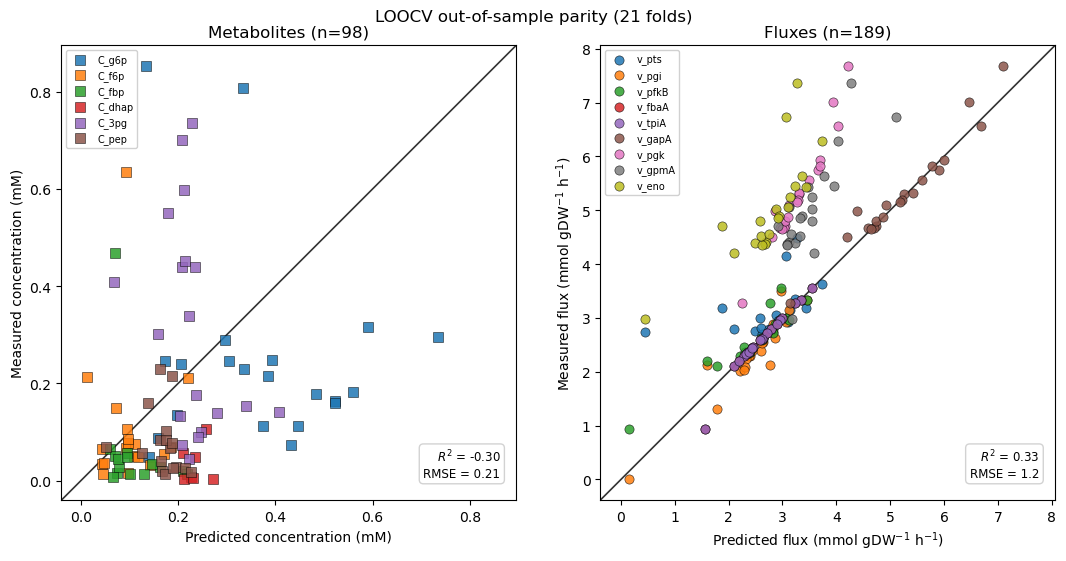

In [12]:
from sklearn.metrics import r2_score, root_mean_squared_error

SPECIES_ROWS = [('C_', 'Metabolites', 'concentration (mM)', 's'),
                ('v_', 'Fluxes', 'flux (mmol gDW$^{-1}$ h$^{-1}$)', 'o')]

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, (prefix, row_label, unit, marker) in zip(axes, SPECIES_ROWS):
    species = [c for c in real_df.columns if c.startswith(prefix)]
    allx, ally = [], []
    for s in species:
        sx, sy = [], []
        for cond in real_df.index:
            if cond not in pred_df.index:
                continue
            rv, pv = real_df.loc[cond, s], pred_df.loc[cond, s]
            if np.isfinite(rv) and np.isfinite(pv):
                sx.append(float(pv)); sy.append(float(rv))
        if sx:
            ax.scatter(sx, sy, marker=marker, s=44, edgecolor='k', linewidth=0.4, alpha=0.85, zorder=3, label=s)
            allx += sx; ally += sy

    if allx:
        x, y = np.array(allx), np.array(ally)
        lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
        pad = 0.05 * (hi - lo) if hi > lo else 1.0
        lo2, hi2 = lo - pad, hi + pad
        ax.plot([lo2, hi2], [lo2, hi2], '-', color='#333333', lw=1.2, zorder=2)
        ax.set_xlim(lo2, hi2); ax.set_ylim(lo2, hi2)
        ax.set_aspect('equal')
        r2 = r2_score(y, x)
        rmse = root_mean_squared_error(y, x)
        ax.text(0.965, 0.045,
                r'$R^2$ = %.2f' % r2 + '\n' + r'RMSE = %.2g' % rmse,
                transform=ax.transAxes, va='bottom', ha='right', fontsize=8.5,
                bbox=dict(boxstyle='round,pad=0.35', fc='white', ec='#cfcfcf', alpha=0.92))
        ax.set_title("%s (n=%d)" % (row_label, len(x)))
    else:
        ax.text(0.5, 0.5, 'no finite paired points', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(row_label)

    ax.set_xlabel('Predicted ' + unit)
    ax.set_ylabel('Measured ' + unit)
    ax.legend(fontsize=7, loc='upper left', framealpha=0.9)

fig.suptitle('LOOCV out-of-sample parity (%d folds)' % len(HELD_OUT_CONDITIONS))
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "parity_loocv_oos.pdf"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(FIG_DIR, "parity_loocv_oos.jpg"), dpi=600, bbox_inches="tight", facecolor="white")
plt.show()


## Parameter stability across LOOCV folds

The prediction-parity plot above can look similar to the full-data
(`third_estimation`) fit even when the underlying parameters shift a lot
fold-to-fold -- some conditions may be highly informative for specific
parameters, or the model may be "sloppy" (many different parameter
combinations giving near-identical predictions). This section makes the
parameter side of LOOCV visible: for each of the 16 free parameters, its
value across the 21 folds against the full-data reference, plus a numeric
summary table (mean/std/CV%/min/max and the single held-out condition that
shifts each parameter the most).


In [13]:
theta_stability_summary = pd.DataFrame({
    "third_estimation_value": theta_fitted_third.loc[free_params, "value"],
    "loocv_mean": theta_by_fold_df[free_params].mean(),
    "loocv_std": theta_by_fold_df[free_params].std(),
    "loocv_min": theta_by_fold_df[free_params].min(),
    "loocv_max": theta_by_fold_df[free_params].max(),
})
theta_stability_summary["loocv_cv_pct"] = (
    100.0 * theta_stability_summary["loocv_std"] / theta_stability_summary["loocv_mean"].abs()
)
theta_stability_summary["most_influential_condition"] = [
    (theta_by_fold_df[p] - theta_fitted_third.loc[p, "value"]).abs().idxmax() for p in free_params
]

theta_stability_summary.to_csv(os.path.join(RESULTS_DIR, "theta_stability_summary.csv"))
print("theta stability summary (sorted by CV%, most variable first):")
print(theta_stability_summary.sort_values("loocv_cv_pct", ascending=False).round(4).to_string())


theta stability summary (sorted by CV%, most variable first):
            third_estimation_value  loocv_mean  loocv_std  loocv_min  loocv_max  loocv_cv_pct most_influential_condition
Ks_fbp_4                    0.0031      1.0191     3.1887     0.0027    10.7808      312.8999                       KO22
kcat_f_4                    3.6701     45.1943   129.2182     3.4791   453.4138      285.9172                       KO22
Ka2_1                       0.0817      0.1225     0.2987     0.0016     0.9435      243.8626                       KO22
Ks_2pg_9                    0.4667      1.0901     2.6389     0.0018     8.9828      242.0706                       KO04
Ks_g6p_pgi                  6.8459      6.0545     1.5572     1.7901     8.0505       25.7200                       KO03
Ks_3pg_8                    2.1855      2.3410     0.5530     1.6832     3.3202       23.6222                       KO15
kcat_f_9                  284.4110    349.7147    77.6174   297.0761   540.8048       22.19

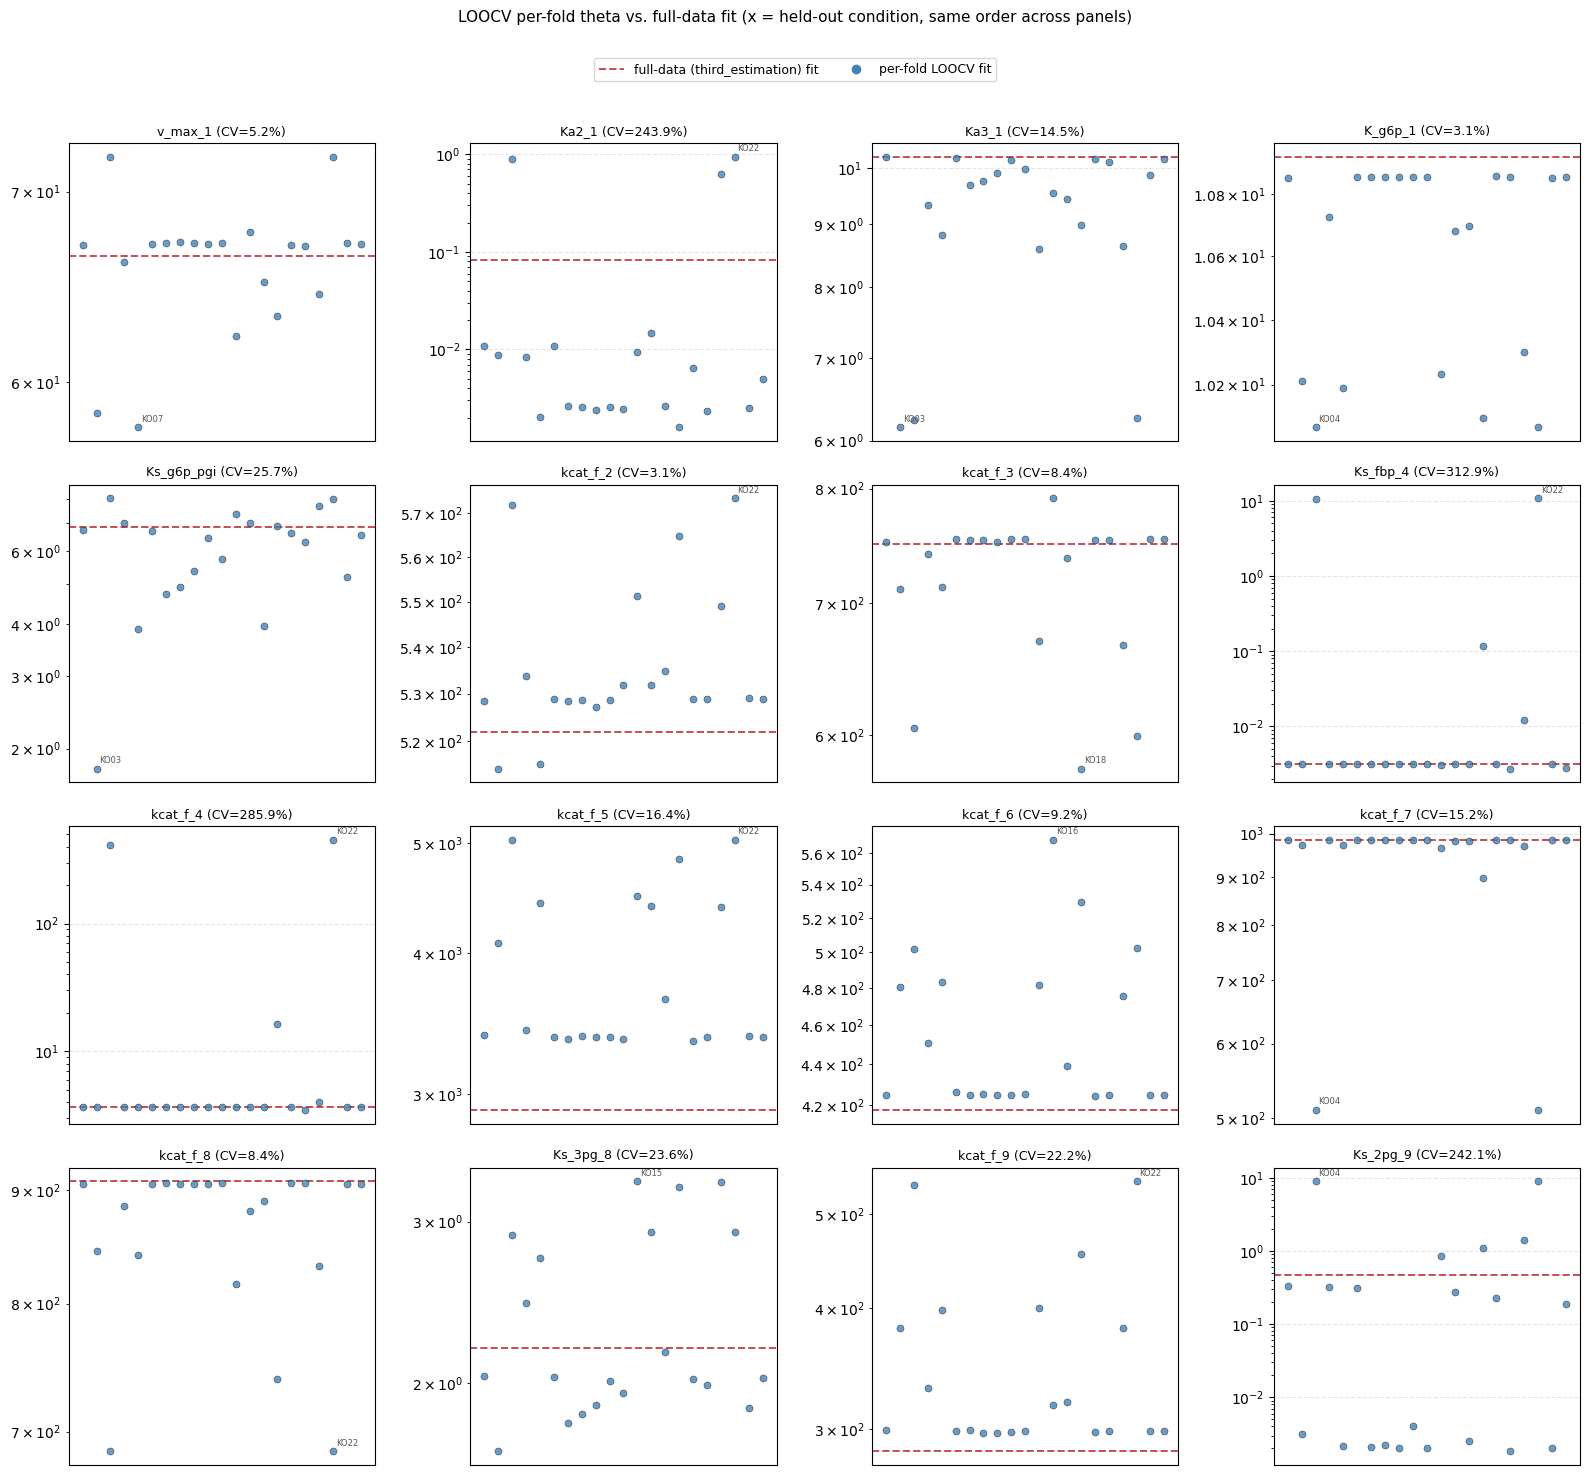

In [15]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(4, 4, figsize=(16, 14))
x = np.arange(len(HELD_OUT_CONDITIONS))

for ax, param in zip(axes.ravel(), free_params):
    vals = theta_by_fold_df.loc[HELD_OUT_CONDITIONS, param].astype(float)
    ref = float(theta_fitted_third.loc[param, "value"])
    cv = theta_stability_summary.loc[param, "loocv_cv_pct"]
    worst_cond = theta_stability_summary.loc[param, "most_influential_condition"]
    worst_i = HELD_OUT_CONDITIONS.index(worst_cond)

    ax.scatter(x, vals.to_numpy(), s=26, alpha=0.8, color="steelblue",
               edgecolor="k", linewidth=0.3, zorder=3)
    ax.axhline(ref, color="#c44e52", lw=1.4, ls="--", zorder=2)
    ax.annotate(worst_cond, xy=(worst_i, vals.loc[worst_cond]), fontsize=6,
                color="#555555", xytext=(2, 4), textcoords="offset points")

    ax.set_title("%s (CV=%.1f%%)" % (param, cv), fontsize=9)
    ax.set_xticks([])
    ax.set_yscale("log")
    ax.grid(axis="y", linestyle="--", alpha=0.3)

handles = [Line2D([], [], color="#c44e52", lw=1.4, ls="--", label="full-data (third_estimation) fit"),
           Line2D([], [], marker="o", ls="", color="steelblue", label="per-fold LOOCV fit")]
fig.legend(handles=handles, loc="upper center", ncol=2, fontsize=9, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("LOOCV per-fold theta vs. full-data fit (x = held-out condition, same order across panels)",
             y=1.05, fontsize=11)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "loocv_theta_stability.pdf"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(FIG_DIR, "loocv_theta_stability.jpg"), dpi=600, bbox_inches="tight", facecolor="white")
plt.show()
